In [341]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.patches as patches
from PIL import Image
import cv2
import numpy as np

ROOT_DIR = Path.cwd().parent
DATA_DIR = ROOT_DIR/"Data"
DET_VAL_DIR = DATA_DIR/"VisDrone2019-DET-val"
IMAGE_DIR = DET_VAL_DIR/"images"
ANNOTATIONS_DIR = DET_VAL_DIR/"annotations"

if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))
    
from utils import CLASS_MAPPING, COCO_NAMES

# Helper Functions

In [342]:
def get_ground_truth_bounding_boxes(image_name: str) -> pd.DataFrame:
    gt_entries = []
    txt_path = ANNOTATIONS_DIR / f"{image_name}.txt"

    with open(txt_path, mode="r", encoding="UTF-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            entry = line.split(",")

            # bbox_left (=x1), bbox_top (=y1), bbox_width, bbox_height, score, object_category (=class), truncation, occlusion
            gt_entries.append({
                "image_name": image_name,
                "x1": float(entry[0]),
                "y1": float(entry[1]),
                "width": float(entry[2]),
                "height": float(entry[3]),
                "score": int(entry[4]),
                "class": int(entry[5]),
                "truncation": int(entry[6]),
                "occlusion": int(entry[7]),
            })

    return pd.DataFrame(gt_entries)

def draw_bounding_boxes(df_640:pd.DataFrame, df_1280:pd.DataFrame, image_path:Path)->None:
    image_name = image_path.stem
    
    df_gt = get_ground_truth_bounding_boxes(image_name)
    entries_640 = df_640[df_640["image"]==image_name]
    entries_1280 = df_1280[df_1280["image"]==image_name]
    
    image = Image.open(image_path)
    fig, axes = plt.subplots(1, 3, figsize=(21, 7), sharex=True, sharey=True)
    
    configs = [
        (axes[0], f"Ground Truth (n={len(df_gt)})", df_gt, "lime", True), # last boolean is for is_wh, explained below
        (axes[1], f"imgsz=640 (n={len(entries_640)})", entries_640, "cyan", False),
        (axes[2], f"imgsz=1280 (n={len(entries_1280)})", entries_1280, "magenta", False),
    ]
    
    for ax, title, df_entries, color, is_wh in configs: # is_wh is true for the ground truth as it already contains columns width and height and doesn't need to calculate them
        ax.imshow(image)
        ax.set_title(title, fontsize=14, fontweight="bold")
        ax.axis("off")

        for row in df_entries.itertuples(index=False):
            x1, y1 = row.x1, row.y1
            width = row.width if is_wh else (row.x2 - row.x1)
            height = row.height if is_wh else (row.y2 - row.y1)

            rect = patches.Rectangle((x1, y1), width, height, linewidth=1.5, edgecolor=color, facecolor="none",)
            ax.add_patch(rect)

    plt.tight_layout()
    plt.show()
    

# Qualitative Analysis
This is only for getting a feeling for the data but not to report quantitative results

## Imgsz = 640

In [343]:
input_file = "no_ai_detections_imgsz-640_conf-0.1.csv"
df_640 = pd.read_csv(str(ROOT_DIR/f"Results/Phase1/{input_file}"), header=0, sep=";")
df_640.head()

,image,x1,y1,x2,y2,class,conf,width,height
0,0000001_02999_d_0000005,443.136475,537.388550,502.354614,591.518005,2,0.512813,1920,1080
1,0000001_02999_d_0000005,761.002747,324.441040,824.853516,377.219727,2,0.291104,1920,1080
2,0000001_02999_d_0000005,946.241638,590.175171,1013.095642,690.291016,7,0.290809,1920,1080
3,0000001_02999_d_0000005,704.611145,334.738403,799.966370,409.736481,2,0.281552,1920,1080
4,0000001_02999_d_0000005,1551.733154,588.470337,1581.186768,664.284973,0,0.277220,1920,1080


### Find images that find no detection at all (class 99)

In [344]:
no_classifications_640 = list(df_640[df_640["class"]==99]["image"])
no_classifications_640

['0000103_04948_d_0000035',
 '0000244_06388_d_0000014',
 '0000253_00001_d_0000001',
 '0000276_05601_d_0000535',
 '0000276_05801_d_0000536',
 '0000287_05001_d_0000782',
 '0000333_00001_d_0000001',
 '0000333_01765_d_0000010',
 '0000333_01961_d_0000011',
 '0000333_02157_d_0000012',
 '0000333_02353_d_0000013',
 '0000333_02549_d_0000014',
 '0000333_02745_d_0000015',
 '0000333_02941_d_0000016',
 '0000333_03137_d_0000017',
 '0000333_03333_d_0000018',
 '0000333_03725_d_0000020']

Showing image: 0000333_03333_d_0000018.jpg


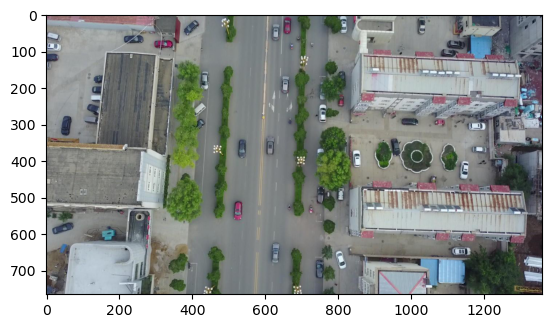

In [345]:
i = 15 # vary to display different images

image_name = f"{no_classifications_640[i]}.jpg"
img_path = f'{IMAGE_DIR}/{image_name}'
print(f"Showing image: {image_name}")
img = mpimg.imread(img_path)
imgplot = plt.imshow(img)
plt.show()

## Imgsz = 1280

In [346]:
input_file = "no_ai_detections_imgsz-1280_conf-0.1.csv"
df_1280 = pd.read_csv(str(ROOT_DIR/f"Results/Phase1/{input_file}"), header=0, sep=";")
df_1280.head()

,image,x1,y1,x2,y2,class,conf,width,height
0,0000001_02999_d_0000005,607.270203,364.121246,707.025146,412.594116,2,0.879883,1920,1080
1,0000001_02999_d_0000005,703.849243,345.165985,802.849426,408.218903,2,0.763361,1920,1080
2,0000001_02999_d_0000005,749.985535,322.938660,828.231445,377.743469,2,0.670596,1920,1080
3,0000001_02999_d_0000005,618.208801,279.460968,721.528931,354.060150,7,0.591055,1920,1080
4,0000001_02999_d_0000005,864.760803,315.718079,876.514709,355.023407,0,0.572179,1920,1080


### Find images containing no detections at all (class 99)

In [347]:
no_classifications_1280 = list(df_1280[df_1280["class"]==99]["image"])
print(len(no_classifications_1280))
print(no_classifications_1280 == no_classifications_640)
print(set(no_classifications_1280).issubset(set(no_classifications_640)))

11
False
True


So all images with no detections at imgsz=1280 already had no detection in imgsz=640

Showing image: 0000333_03725_d_0000020.jpg


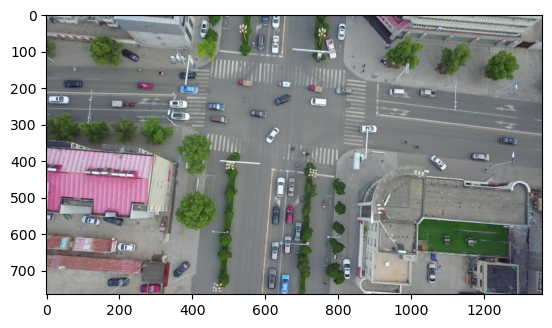

In [348]:
h = 10 # vary to display different images

image_name = f"{no_classifications_1280[h]}.jpg"
img_path = f'{IMAGE_DIR}/{image_name}'
print(f"Showing image: {image_name}")
img = mpimg.imread(img_path)
imgplot = plt.imshow(img)
plt.show()

## Combining imgsz=640 and imgsz=1280

In [349]:
print(f"Number of Detections for imgsz=640: {len(df_640)}")
print(f"Number of Detections for imgsz=1280: {len(df_1280)}")


Number of Detections for imgsz=640: 16068
Number of Detections for imgsz=1280: 29828


### Comparing different imgsz to each other

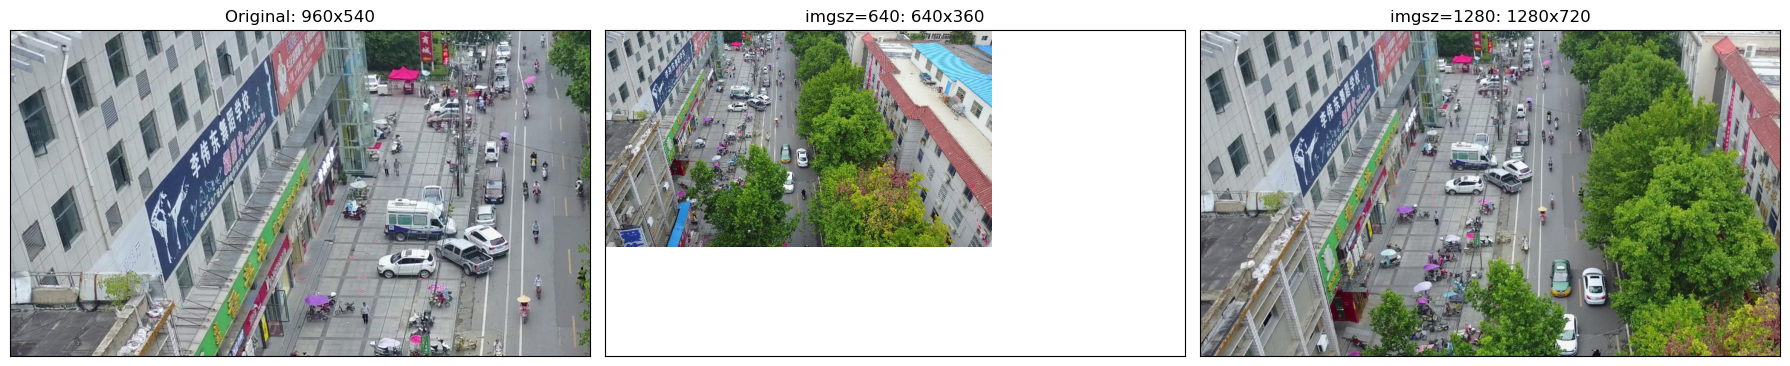

In [350]:
j = 1 # vary to display different images
image_name = "0000001_02999_d_0000005.jpg"
# image_name = f"{no_classifications_1280[j]}.jpg" 
img_path = f'{IMAGE_DIR}/{image_name}'

img_original_bgr = cv2.imread(img_path)
img_original = cv2.cvtColor(img_original_bgr, cv2.COLOR_BGR2RGB)
w_orig = df_640[df_640["image"]==no_classifications_640[j]]["width"].item()
h_orig = df_640[df_640["image"]==no_classifications_640[j]]["height"].item()
scale_factor = max(w_orig, h_orig)/min(w_orig, h_orig)

# all images have bigger width than height!
# testes with:
# df_640[df_640["width"]<df_640["height"]]
# gives empty df

w_640 = 640
h_640 = int(w_640//scale_factor)

w_1280 = 1280
h_1280 = int(w_1280//scale_factor)

img_640 = cv2.resize(img_original, (w_640, h_640))
img_1280 = cv2.resize(img_original, (w_1280, h_1280))

images = [img_original, img_640, img_1280]
titles = [f"Original: {w_orig}x{h_orig}", f"imgsz=640: {w_640}x{h_640}", f"imgsz=1280: {w_1280}x{h_1280}"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title)
    ax.set_xlim(0, w_orig)
    ax.set_ylim(h_orig, 0)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

### Plot Detection bounding boxes

In [351]:
unique_640_no_detections = [image for image in no_classifications_640 if image not in no_classifications_1280]
print(len(unique_640_no_detections))
unique_1280_no_detections = [image for image in no_classifications_1280 if image not in no_classifications_640]
print(len(unique_1280_no_detections))

6
0


0000333_00001_d_0000001.jpg


,image_name,x1,y1,width,height,score,class,truncation,occlusion
0,0000333_00001_d_0000001,267.0,429.0,66.0,29.0,1,4,0,0
1,0000333_00001_d_0000001,175.0,421.0,66.0,31.0,1,4,0,0
2,0000333_00001_d_0000001,346.0,426.0,67.0,28.0,1,4,0,0
3,0000333_00001_d_0000001,325.0,466.0,65.0,26.0,1,4,0,0
4,0000333_00001_d_0000001,246.0,468.0,58.0,26.0,1,4,0,0
...,...,...,...,...,...,...,...,...,...
66,0000333_00001_d_0000001,576.0,651.0,25.0,65.0,1,4,0,0
67,0000333_00001_d_0000001,1012.0,344.0,19.0,10.0,1,10,0,1
68,0000333_00001_d_0000001,1018.0,344.0,10.0,9.0,1,2,0,1
69,0000333_00001_d_0000001,301.0,548.0,119.0,49.0,0,0,0,0


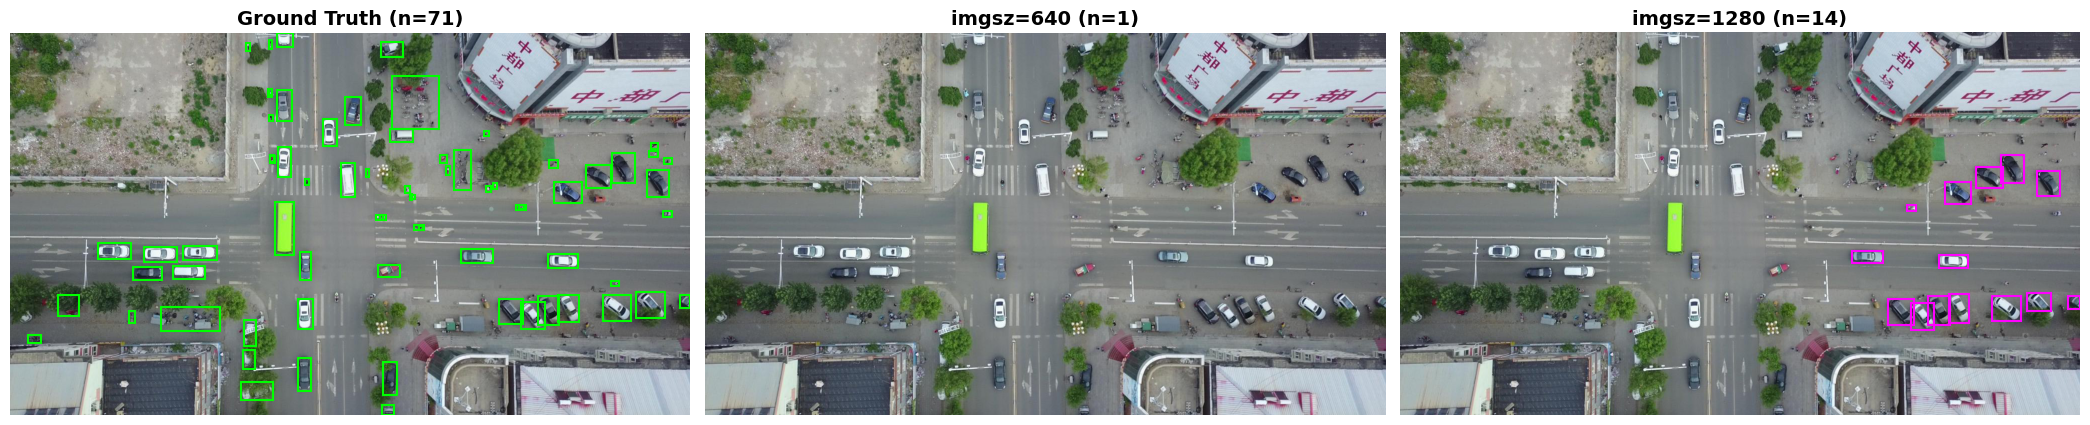

In [352]:
k = 5
print(f"{unique_640_no_detections[k]}.jpg")
pd_gt = get_ground_truth_bounding_boxes(unique_640_no_detections[k])


display(pd_gt)
draw_bounding_boxes(df_640, df_1280, Path(IMAGE_DIR/f"{unique_640_no_detections[k]}.jpg"))

# Quantitative Analysis

## Ground Truth table and Matching

In [353]:
def load_ground_truth() -> pd.DataFrame:
    # read all input files and concatenate all gt detections
    frames = []
    for txt_file in sorted(ANNOTATIONS_DIR.glob("*.txt")):
        frames.append(get_ground_truth_bounding_boxes(txt_file.stem))
        
    df_gt = pd.concat(frames, ignore_index=True)
    df_gt = df_gt.rename(columns={"image_name": "image", "class": "vis_class", "width": "bbox_width", "height": "bbox_height"}) # rename class column to vis_class for VisDrone classes
    df_gt["vis_class"] -= 1 # the annotation files are 1-based while CLASS_MAPING is 0-based so we need to calculate -1, for example, the official documentation only states classes 0-9, but already the first annotation files contains gt class label 10
    # filter out score=0 and class=99 (so no detections were found) and trycicle and awning-tricycle, which are not in the CLASS Maping keys
    df_gt = df_gt[(df_gt["score"]==1) & (df_gt["vis_class"].isin(CLASS_MAPPING.keys()))]
    df_gt.insert(7, "coco_class", df_gt["vis_class"].map(CLASS_MAPPING))
    df_gt.insert(2, "x2", df_gt["x1"] + df_gt["bbox_width"])
    df_gt.insert(4, "y2", df_gt["y1"] + df_gt["bbox_height"])
    
    
    return df_gt.reset_index(drop=True)

def IoU_mapping(a, b): # a containing n boxes and b containing m boxes each containing x1, x2, y1, y2, returns an n*m matrix with the IoU scores
    """
    Strictly requires the ordering: x1, x2, y1, y2
    """
    # intersecting area calculates as follows:
    # (min(x2) - max(x1))*(min(y2)-max(y1))
    int_width = np.minimum(a[:, None, 1], b[None,:,1]) - np.maximum(a[:, None, 0], b[None,:,0]) # a[:,0] would be of shape (n,) but for broadcasting we want (n,1) to broadcast to (1,m) of b which we get with b[None,:,0] (0 for x1)
    int_height = np.minimum(a[:, None, 3], b[None,:,3]) - np.maximum(a[:, None, 2], b[None,:,2])
    inter = np.clip(int_width, 0, None) * np.clip(int_height, 0, None) # None was we need no maximum but Numpy could require an argument to be given so we just give the standard value None
    area_a = (a[:, 1]- a[:, 0])*(a[:, 3]-a[:, 2]) # (n,)
    area_b = (b[:, 1]- b[:, 0])*(b[:, 3]-b[:, 2]) # (m,)
    union = area_a[:, None] + area_b[None, :] - inter #(n, m)
    return inter/(union+1e-9) # add a small value 1e-9 to prevent division by 0 if both boxes have 0 area

def image_matching(gt:pd.DataFrame, det:pd.DataFrame, iou_thr=0.7, conf_thr=0.1):
    det = det[(det["class"]!=99) & (det["conf"]>=conf_thr)]
    found = np.zeros(len(gt), dtype=bool) # store for each gt object if it was detected
    det_by_img = {im: dets for im, dets in det.groupby("image")}
    for img, gt_dets in gt.groupby("image"): # loop over all gt images
        if img not in det_by_img: # continue if image in gt but not in detections df
            continue
        
        img_dets = det_by_img[img]
        iou = IoU_mapping(gt_dets[["x1", "x2", "y1", "y2"]].to_numpy(float), img_dets[["x1", "x2", "y1", "y2"]].to_numpy(float))
        # set IoU with mismatching classes to 0
        iou[gt_dets["coco_class"].to_numpy()[:, None] != img_dets["class"].to_numpy()[None, :]] = 0
        gt_idx = gt_dets.index.to_numpy()
        while True:
            i, j = np.unravel_index(iou.argmax(), iou.shape) # returns the coordinates of the max instead of just the index, so we get the max
            if iou[i, j] < iou_thr:
                break
            found[gt_idx[i]] = True
            # each GT and each detection is used only once, so we need to set row and column to 0
            iou[i, :] = 0
            iou[:, j] = 0   
    return found

gt = load_ground_truth()
input_image_size = (df_640.drop_duplicates("image").set_index("image")[["width", "height"]].rename(columns={"width": "img_width", "height": "img_height"}))
gt = gt.join(input_image_size, on="image")
gt["size_orig"] = np.sqrt(gt["bbox_width"]*gt["bbox_height"]) # calculate bounding box size as sqrt of bbox_width * bbox_height
for imgsz, df_det in [(640, df_640), (1280, df_1280)]:
    gt[f"found_{imgsz}"] = image_matching(gt, df_det)
    gt[f"size_eff_{imgsz}"] = gt["size_orig"] * imgsz / np.maximum(gt["img_width"], gt["img_height"])

gt["class_name"] = gt["coco_class"].map(COCO_NAMES)
gt

,image,x1,x2,y1,y2,bbox_width,bbox_height,score,vis_class,coco_class,truncation,occlusion,img_width,img_height,size_orig,found_640,size_eff_640,found_1280,size_eff_1280,class_name
0,0000001_02999_d_0000005,871.0,925.0,572.0,664.0,54.0,92.0,1,3,2,0,0,1920,1080,70.484041,True,23.494680,False,46.989360,car
1,0000001_02999_d_0000005,948.0,1010.0,592.0,684.0,62.0,92.0,1,3,2,0,0,1920,1080,75.524830,True,25.174943,False,50.349887,car
2,0000001_02999_d_0000005,874.0,941.0,705.0,815.0,67.0,110.0,1,3,2,0,1,1920,1080,85.848704,False,28.616235,False,57.232469,car
3,0000001_02999_d_0000005,971.0,998.0,791.0,845.0,27.0,54.0,1,9,3,0,1,1920,1080,38.183766,False,12.727922,False,25.455844,motorcycle
4,0000001_02999_d_0000005,976.0,995.0,794.0,832.0,19.0,38.0,1,1,0,0,1,1920,1080,26.870058,False,8.956686,False,17.913372,person
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37177,0000364_01765_d_0000782,383.0,390.0,201.0,215.0,7.0,14.0,1,0,0,0,1,960,540,9.899495,False,6.599663,False,13.199327,person
37178,0000364_01765_d_0000782,535.0,563.0,146.0,159.0,28.0,13.0,1,3,2,0,0,960,540,19.078784,True,12.719189,True,25.438379,car
37179,0000364_01765_d_0000782,225.0,303.0,148.0,169.0,78.0,21.0,1,8,5,0,1,960,540,40.472213,False,26.981475,False,53.962950,bus
37180,0000364_01765_d_0000782,2.0,153.0,336.0,502.0,151.0,166.0,1,5,7,1,1,960,540,158.322456,False,105.548304,False,211.096608,truck


**Recall per Image Size**

In [354]:
gt[["found_640","found_1280"]].mean()

found_640     0.175407
found_1280    0.322226
dtype: float64

**Recall per class**

In [355]:
gt.groupby("coco_class")[["found_640","found_1280"]].mean()

,found_640,found_1280
coco_class,,
0,0.069654,0.217338
1,0.003108,0.020979
2,0.330819,0.515182
3,0.018011,0.082890
5,0.179283,0.310757
7,0.141333,0.229333


In [356]:
gt.groupby("class_name")[["found_640","found_1280"]].mean()


,found_640,found_1280
class_name,,
bicycle,0.003108,0.020979
bus,0.179283,0.310757
car,0.330819,0.515182
motorcycle,0.018011,0.082890
person,0.069654,0.217338
truck,0.141333,0.229333


**Improvement/Worsening**

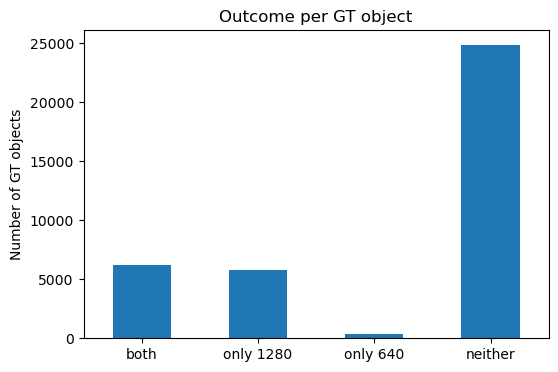

outcome,both,only 1280,only 640,neither
class_name,,,,
bicycle,0.002,0.019,0.001,0.978
bus,0.163,0.147,0.016,0.673
car,0.320,0.195,0.011,0.474
motorcycle,0.014,0.069,0.004,0.913
person,0.062,0.156,0.008,0.775
truck,0.115,0.115,0.027,0.744


In [357]:
gt["outcome"] = np.select(
    [gt["found_640"] & gt["found_1280"], gt["found_1280"], gt["found_640"]],
    ["both", "only 1280", "only 640"],
    default="neither",
)
order = ["both", "only 1280", "only 640", "neither"]

counts = gt["outcome"].value_counts().reindex(order)
counts.plot.bar(rot=0, figsize=(6, 4), title="Outcome per GT object")
plt.ylabel("Number of GT objects")
plt.show()

# per class, as share of each class
pd.crosstab(gt["class_name"], gt["outcome"], normalize="index")[order].round(3)


**Recall per Image and Median Object Size**

,,recall_640,recall_1280
img_width,img_height,,
960,540,0.171580,0.286492
1360,765,0.237982,0.390109
1920,1080,0.161227,0.310121


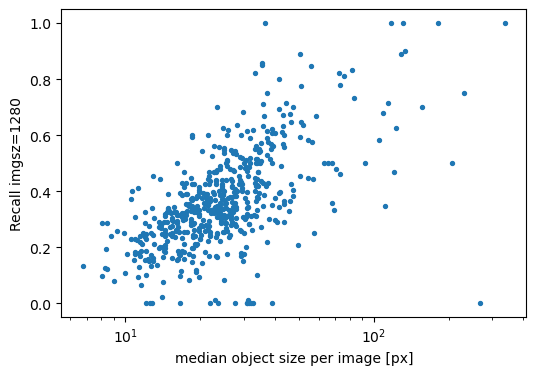

In [ ]:
per_img = gt.groupby("image").agg(
    n_gt=("found_640", "size"),
    recall_640=("found_640", "mean"),
    recall_1280=("found_1280", "mean"),
    img_width=("img_width", "first"),
    img_height=("img_height", "first"),
    median_size=("size_orig", "median"),
)

# by image resolution
display(per_img.groupby(["img_width", "img_height"])[["recall_640", "recall_1280"]].mean())

# does a smaller median object size explain low recall?
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(per_img["median_size"], per_img["recall_1280"], s=8)
ax.set_xscale("log")
ax.set_xlabel("median object size per image [px]")
ax.set_ylabel("Recall imgsz=1280")
plt.show()


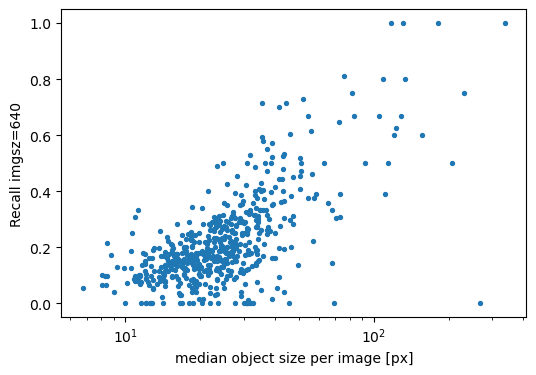

In [359]:
# does a smaller median object size explain low recall?
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(per_img["median_size"], per_img["recall_640"], s=8)
ax.set_xscale("log")
ax.set_xlabel("median object size per image [px]")
ax.set_ylabel("Recall imgsz=640")
plt.show()

**Objects per image vs recall**

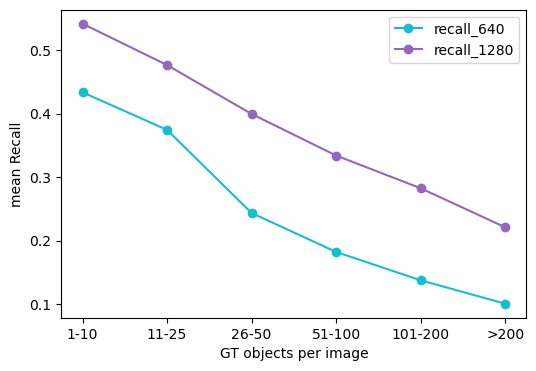

In [360]:
per_img["n_bin"] = pd.cut(per_img["n_gt"], [0, 10, 25, 50, 100, 200, np.inf],
                          labels=["1-10", "11-25", "26-50", "51-100", "101-200", ">200"])
recall = per_img.groupby("n_bin", observed=True)[["recall_640", "recall_1280"]].mean()

recall.plot(marker="o", color=["tab:cyan", "tab:purple"], figsize=(6, 4))
plt.xticks(range(len(recall)), recall.index)
plt.xlabel("GT objects per image")
plt.ylabel("mean Recall")
plt.show()


**Sensitivity to IoU Threshould**

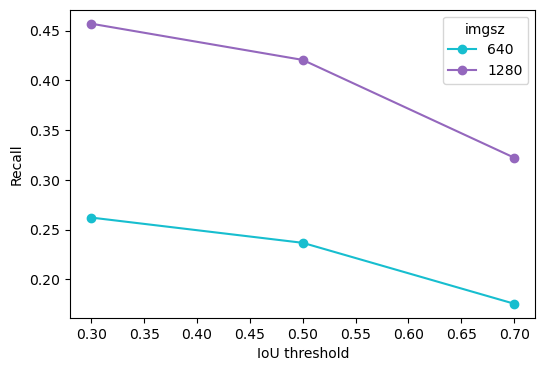

imgsz,640,1280
iou_thr,,
0.3,0.261982,0.456861
0.5,0.236620,0.420472
0.7,0.175407,0.322226


In [361]:
rows = []
for thr in [0.3, 0.5, 0.7]:
    for imgsz, df_det in [(640, df_640), (1280, df_1280)]:
        found = image_matching(gt, df_det, iou_thr=thr)
        rows.append({"iou_thr": thr, "imgsz": imgsz, "recall": found.mean()})

iou_sens = pd.DataFrame(rows).pivot(index="iou_thr", columns="imgsz", values="recall")
iou_sens.plot(marker="o", color=["tab:cyan", "tab:purple"], figsize=(6, 4))
plt.xlabel("IoU threshold")
plt.ylabel("Recall")
plt.show()
iou_sens


## Recall vs Object sizes per Image Class

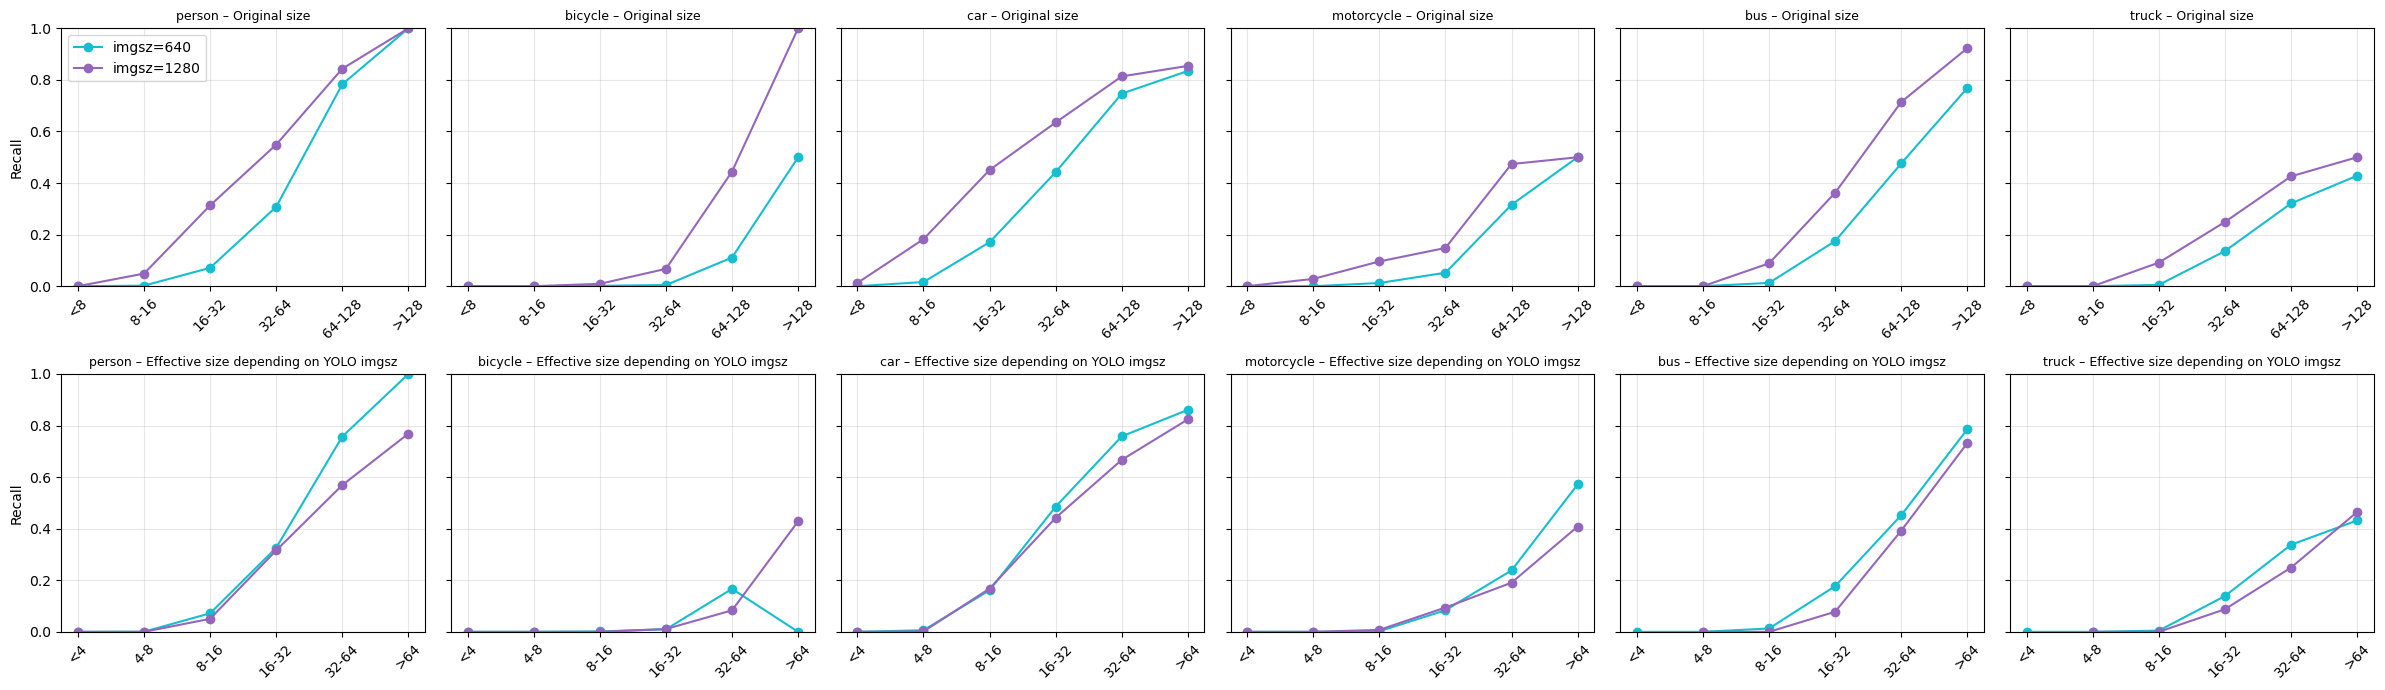

In [362]:
bins_orig = [0, 8, 16, 32, 64, 128, np.inf] # medians of classes are between 17 and 39 so we try to capture those with more bins
bins_eff  = [0, 4, 8, 16, 32, 64, np.inf]
labels_orig = ["<8", "8-16", "16-32", "32-64", "64-128", ">128"]
labels_eff  = ["<4", "4-8", "8-16", "16-32", "32-64", ">64"]

def recall_by_size(gt, found_col, size_col, bins, labels):
    b = pd.cut(gt[size_col], bins=bins, labels=labels)
    return gt.groupby(b, observed=False)[found_col].agg(recall="mean", n="size") # mean column will be called recall and n column called size

classes = sorted(gt["coco_class"].unique())
fig, axes = plt.subplots(2, len(classes), figsize=(4 * len(classes), 7), sharey=True)
for row, (kind, title) in enumerate([("orig", "Original size"), ("eff", "Effective size depending on YOLO imgsz")]):
    for ax, c in zip(axes[row], classes):
        sub = gt[gt["coco_class"] == c]
        for imgsz, color in [(640, "tab:cyan"), (1280, "tab:purple")]:
            col = "size_orig" if kind == "orig" else f"size_eff_{imgsz}"
            bins = bins_orig if kind == "orig" else bins_eff
            labels = labels_orig if kind == "orig" else labels_eff
            r_by_size = recall_by_size(sub, f"found_{imgsz}", col, bins, labels)
            ax.plot(r_by_size.index.astype(str), r_by_size["recall"], marker="o", color=color, label=f"imgsz={imgsz}")
        ax.set_title(f"{COCO_NAMES[c]} – {title}", fontsize=9)
        ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=45); ax.grid(alpha=.3)
axes[0, 0].legend(); axes[0, 0].set_ylabel("Recall"); axes[1, 0].set_ylabel("Recall")
plt.tight_layout(); plt.show()

